# Chapitre 6 - Cours 2 : rééquilibrer les partitions

Un cluster ne garde pas la même taille toute sa vie : les données et le débit
grossissent, des machines tombent en panne et sont remplacées. Il faut alors **déplacer**
des données d'un nœud à l'autre : c'est le **rééquilibrage**. Ce notebook couvre la
section *Rebalancing Partitions* : *Strategies for Rebalancing* (*How not to do it: hash
mod N*, *Fixed number of partitions*, *Dynamic partitioning*, *Partitioning
proportionally to nodes*), l'encadré *Consistent Hashing* de la section *Partitioning by
Hash of Key*, et *Operations: Automatic or Manual Rebalancing*.

**Plan.**

1. Ce qu'on attend d'un rééquilibrage, et la borne inférieure du volume à déplacer.
2. Ce qu'il ne faut pas faire : haché modulo le nombre de nœuds.
3. Un nombre fixe de partitions, plus nombreuses que les nœuds.
4. Le partitionnement dynamique : des partitions qui se scindent.
5. Des partitions proportionnelles aux nœuds, et le hachage cohérent.
6. Rééquilibrage automatique ou manuel : le risque de cascade.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Wedge

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")
KEYS = np.arange(200_000)                       # 200 000 clés entières pour toutes les mesures

## 1. Ce qu'on attend d'un rééquilibrage (section *Rebalancing Partitions*)

Trois exigences, quelle que soit la stratégie :

1. **après** le rééquilibrage, la charge (données, lectures, écritures) est de nouveau
   répartie équitablement entre les nœuds ;
2. **pendant** le rééquilibrage, la base continue d'accepter lectures et écritures ;
3. on ne déplace **pas plus de données que nécessaire**, pour que l'opération soit rapide
   et ménage le réseau et les disques.

**La borne inférieure.** Passer de $n$ à $n+1$ nœuds équilibrés impose au nouveau venu de
recevoir $1/(n+1)$ des données ; elles viennent forcément d'ailleurs. Aucune stratégie ne
peut donc déplacer moins de $1/(n+1)$ des clés, et une stratégie **optimale** atteint
exactement cette fraction en ne déplaçant **que vers le nouveau nœud** (aucun échange
entre anciens nœuds). Le diagramme montre ce rééquilibrage idéal pour $n = 3$ : chaque
ancien nœud cède un quart de ses données, soit un douzième du total chacun.

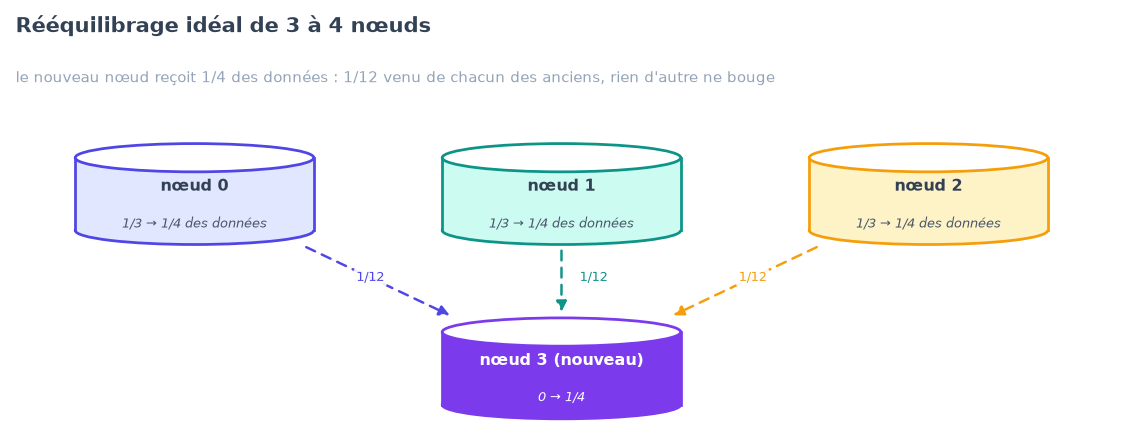

In [2]:
d = Diagram(12, 3.6, title="Rééquilibrage idéal de 3 à 4 nœuds",
            subtitle="le nouveau nœud reçoit 1/4 des données : 1/12 venu de chacun des anciens, rien d'autre ne bouge")
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.box(f"n{i}", 2.0 + i * 4.0, 2.55, f"nœud {i}", sub="1/3 → 1/4 des données", color=c, kind="db", w=2.6, h=1.1)
d.box("new", 6.0, 0.65, "nœud 3 (nouveau)", sub="0 → 1/4", color=VIOLET, kind="db", w=2.6, h=1.1, filled=True)
for i, c in enumerate([INDIGO, TEAL, AMBER]):
    d.arrow(f"n{i}", "new", "1/12", color=c, style="dashed", label_pos=0.45, label_offset=(0.35 if i == 1 else 0, 0))
d.show()

Mesurons maintenant chaque stratégie à cette aune : la **fraction de clés déplacées** lors
de l'ajout d'un nœud, comparée à l'optimum $1/(n+1)$.

> **À retenir.** Un bon rééquilibrage rétablit l'équité, ne bloque pas le service et ne
> déplace que le strict nécessaire : au moins $1/(n+1)$ des données quand on passe de $n$
> à $n+1$ nœuds, et rien entre les anciens nœuds.